# Assignment 2(due on 10/28)

## Student: 孔朝晖（12632723），Github: ASHui0328

## 批改人：张鹏

## 得分：80/100 

In [4]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [5]:
# 1
df1 = pd.read_csv("/home/zhangp/桌面/A2/earthquakes-2026-10-30_17-09-02_+0800.tsv", sep = '\t')  # 助教更改读取路径

In [6]:
# 1.1
df11 = df1.groupby('Country')['Deaths'].sum().sort_values(ascending = False)
print(df11.iloc[0 : 20])

Country
CHINA           2139225.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
HAITI            323484.0
AZERBAIJAN       319251.0
SYRIA            289826.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


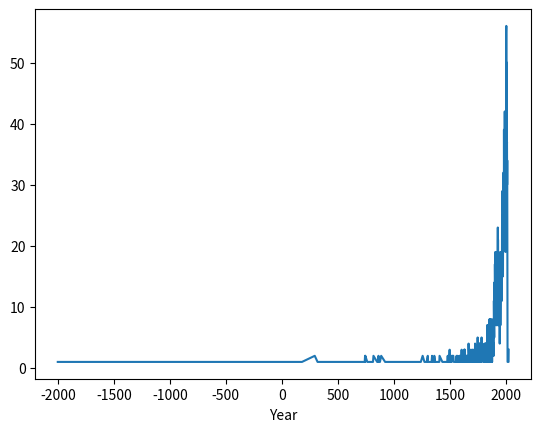

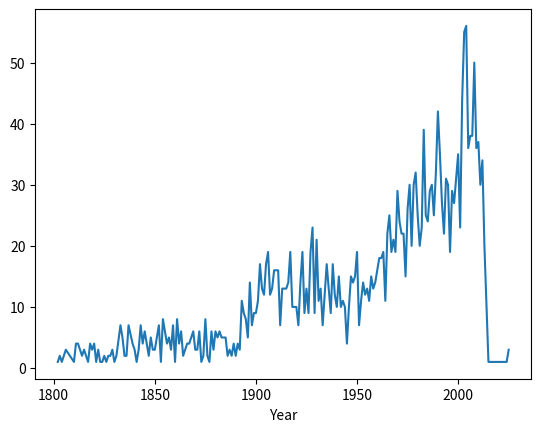

<Axes: xlabel='Year'>

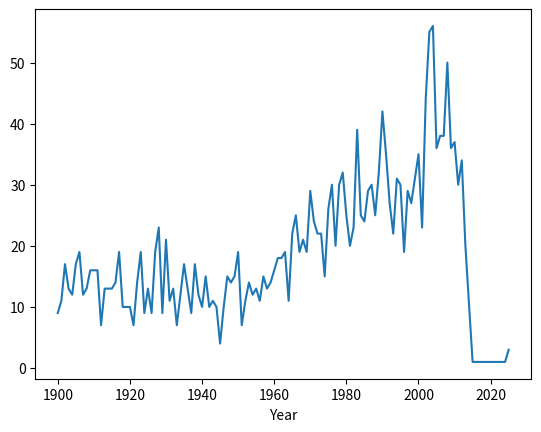

In [7]:
# 1.2
df12 = df1.loc[df1['Ms'] > 3.0].groupby('Year')['Ms'].count()
df12.plot()
plt.show()
df12[df12.index >= 1800].plot()
plt.show()
df12[df12.index >= 1900].plot()
# 地震次数的整体趋势是上升的，但是短时间尺度波动，上升的主要原因是观测能力的提升，波动是随机性和局部因素叠加的结果，地震分布近似泊松过程

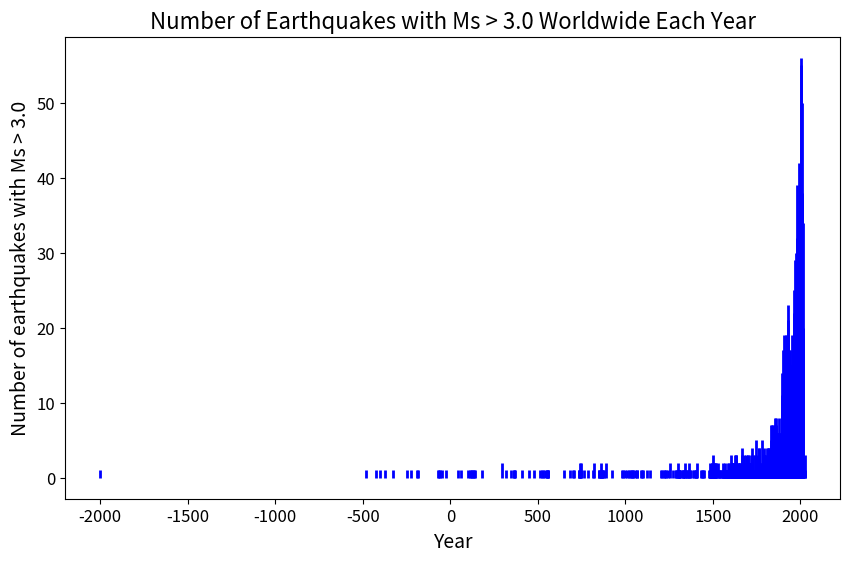

In [9]:
#1.2 助教添加
# 筛选出震级大于6.0的地震
large_quakes = df1[df1['Ms'] > 3.0]

# 按年份对数据进行分组，并得到每年的地震次数
quakes_by_year = large_quakes.groupby('Year')['Ms'].count()

plt.figure(figsize=(10, 6))
plt.vlines(quakes_by_year.index, ymin=0, ymax=quakes_by_year.values, color='blue', linewidth=2)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Number of earthquakes with Ms > 3.0', fontsize=14)
plt.title('Number of Earthquakes with Ms > 3.0 Worldwide Each Year', fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=12)

# Displaying the plot
plt.show()

In [10]:
# 1.3
def CountEq_LargestEq(country):
    n = df1.groupby('Country')['Id'].count()[country.upper()]
    df13 = df1.loc[df1['Country'] == country.upper()].sort_values('Ms', ascending = False).iloc[0]
    date = [df13['Year'], df13['Mo'], df13['Dy']]
    date = ['' if pd.isna(i) else int(i) for i in date]
    location = df13['Location Name']  
    return int(n), f'{date[0]}-{date[1]}-{date[2]}', location

result = [CountEq_LargestEq(c) for c in df1.groupby('Country').size().index]
result.sort(reverse = True)
for r in result:
    print(r)

(627, '1668-7-25', 'CHINA:  SHANDONG PROVINCE')
(429, '2011-3-11', 'JAPAN:  HONSHU')
(427, '2004-12-26', 'INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST')
(385, '856-12-22', 'IRAN:  DAMGHAN, QUMIS')
(359, '1939-12-26', 'TURKEY:  ERZINCAN')
(338, '1915-1-13', 'ITALY:  MARSICA, AVEZZANO, ABRUZZI')
(296, '365-7-21', 'GREECE:  CRETE:  KNOSSOS')
(283, '1964-3-28', 'ALASKA')
(233, '1897-9-21', 'PHILIPPINES:  MINDANAO, ZAMBOANGA, SULU, ISABELA')
(217, '1787-3-28', 'MEXICO:  SAN MARCOS, OAXACA')
(200, '1960-5-22', 'CHILE:  PUERTO MONTT, VALDIVIA')
(195, '1716-2-6', 'PERU:  PUEBLO DE TORATA IN TACNA')
(159, '1952-11-4', 'RUSSIA:  KAMCHATKA PENINSULA')
(107, '1919-5-6', 'PAPUA NEW GUINEA:  SOLOMON ISLANDS')
(103, '1920-6-5', 'TAIWAN')
(102, '1950-8-15', 'INDIA-CHINA')
(83, '1826-6-18', 'COLOMBIA:  ENGATIVA,BOGOTA,RAMIRIQUI,UMBITA,TUNJA')
(72, '1909-7-7', 'AFGHANISTAN:  HINDU-KUSH')
(72, '1826--', 'NEW ZEALAND:  FJORDLAND')
(70, '1906-1-31', 'ECUADOR:  OFF COAST')
(65, '1913-10-14', 'VANUATU ISLANDS

### 第一题代码运行正常，可以输出正确结果，报告中也展示了输出内容。第二问绘图有一点点问题，没有数据的年份不应该有数据，建议绘制竖线图或者删除NAN值后绘图，见上面代码助教添加代码-2。第三题最好选用Mag数据进行分析。代码和报告都没有相应注释和解题思路-1



### 得分：22/25
### --------------------------------------------------------------------------------------------

/tmp/ipykernel_1152784/2019517567.py:2: DtypeWarning: Columns (4,8,9,10,11,14,15,24,25,27,29,31,34,37,38,40,41,45,49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径


Text(0, 0.5, 'monthly mean air temperature')

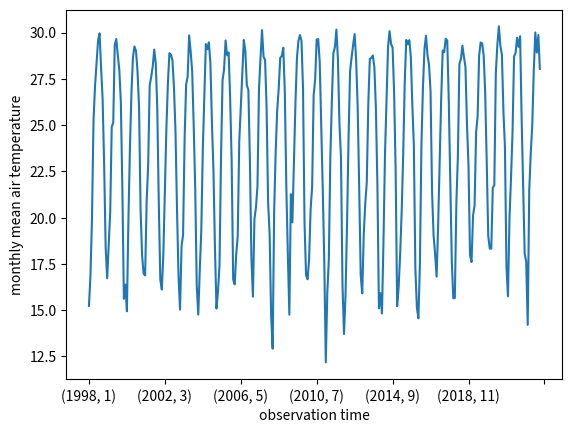

In [11]:
# 2
df2 = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径
vq = df2["TMP"].str.partition(",")
tmp_v = pd.to_numeric(vq[0])
tmp_v = tmp_v.where(tmp_v != 9999, np.nan)
df2['TMP_V'] = tmp_v / 10
df2["Y"] = pd.to_datetime(df2["DATE"]).dt.year
df2["M"] = pd.to_datetime(df2["DATE"]).dt.month
monthly = df2.groupby(["Y", "M"])["TMP_V"].mean()
monthly.plot()
plt.xlabel('observation time')
plt.ylabel('monthly mean air temperature')

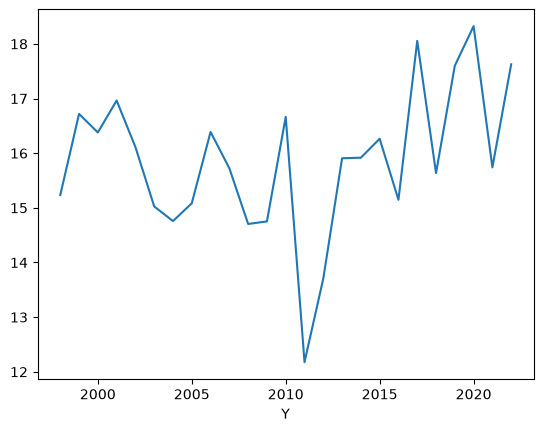

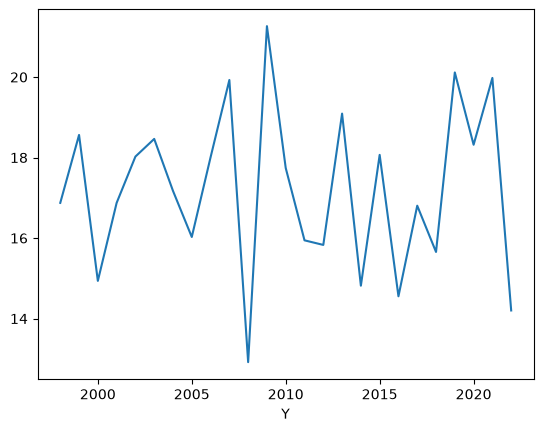

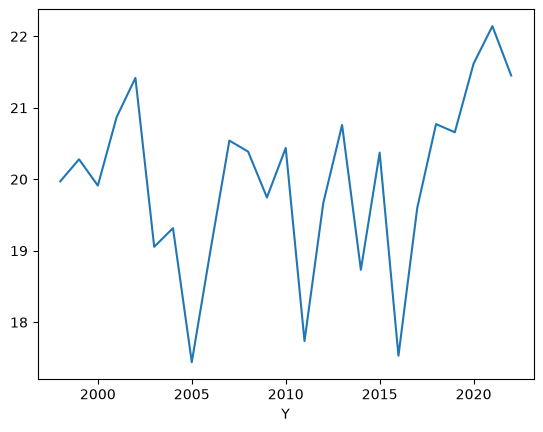

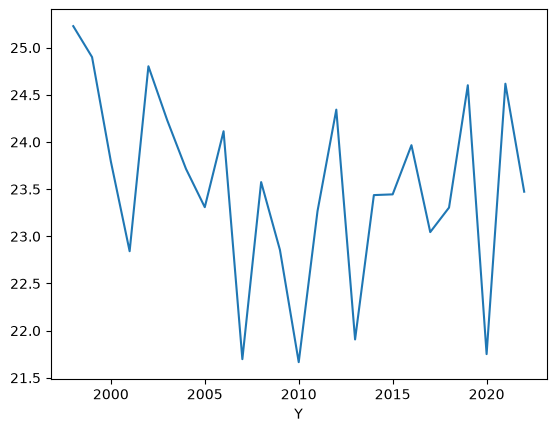

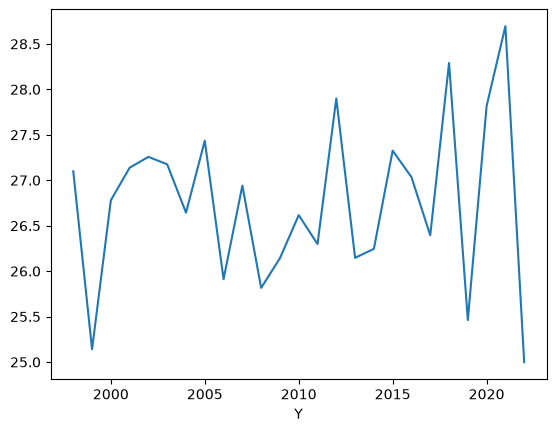

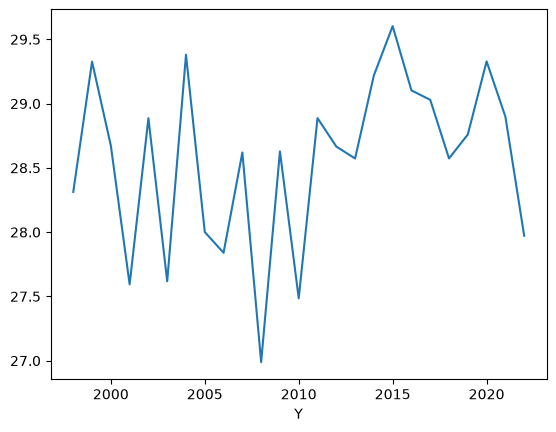

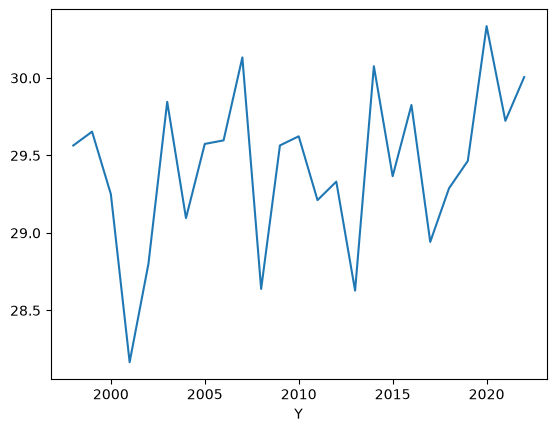

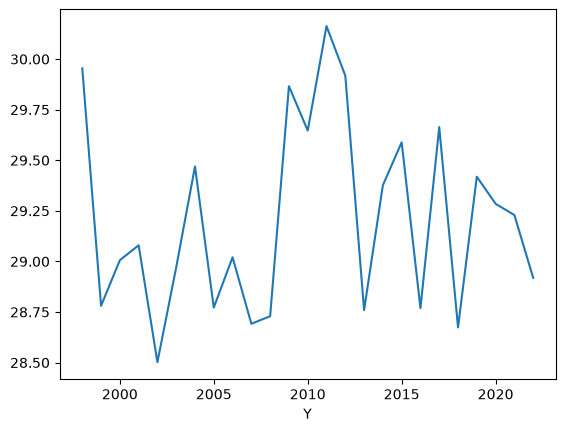

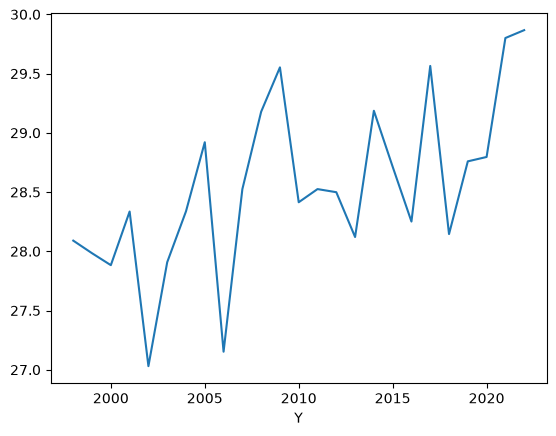

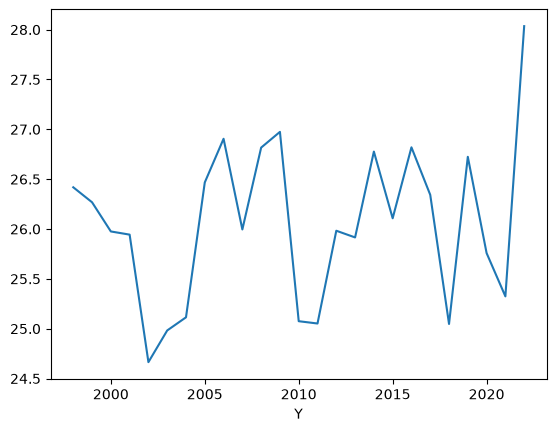

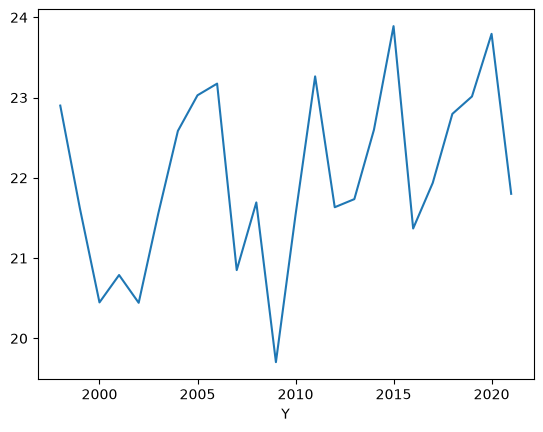

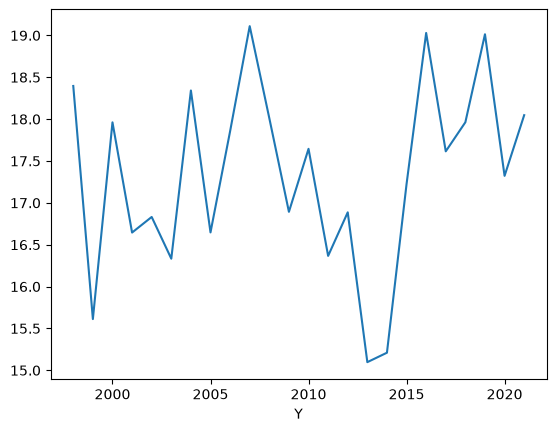

In [78]:
for i in range(12):
    df2.loc[df2['M']==i+1].groupby('Y')['TMP_V'].mean().plot()
    plt.show()

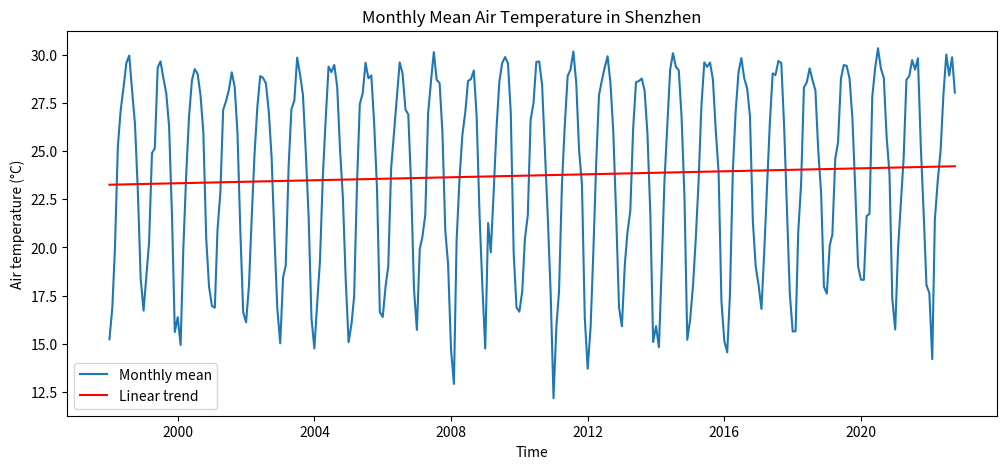

Slope: 0.03873600636339173 °C/year
P-value: 0.33910707287724584


In [12]:
#助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

weather = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv", low_memory=False)  # 助教更改读取路径

tmp = weather["TMP"].str.split(",", expand=True)
weather["time"] = pd.to_datetime(weather["DATE"])
weather["temperature"] = pd.to_numeric(tmp[0], errors="coerce") / 10
weather["quality"] = tmp[1]

weather = weather[
    (tmp[0] != "+9999")
    & weather["quality"].isin(["0", "1", "4", "5", "9"])
]

monthly_temperature = (
    weather.set_index("time")["temperature"]
    .resample("MS")
    .mean()
)

x = (monthly_temperature.index - monthly_temperature.index[0]).days / 365.25
temperature_trend = stats.linregress(x, monthly_temperature.values)

plt.figure(figsize=(12, 5))
plt.plot(monthly_temperature.index, monthly_temperature.values, label="Monthly mean")
plt.plot(
    monthly_temperature.index,
    temperature_trend.intercept + temperature_trend.slope * x,
    color="red",
    label="Linear trend"
)
plt.xlabel("Time")
plt.ylabel("Air temperature (°C)")
plt.title("Monthly Mean Air Temperature in Shenzhen")
plt.legend()
plt.show()

print("Slope:", temperature_trend.slope, "°C/year")
print("P-value:", temperature_trend.pvalue)

### 代码运行正常但是结果有偏差，首先筛选条件不充足，没有排除质量不合格的数据，其次报告中的显著的变暖趋势以及分析依据是怎么计算的，没有代码进行佐证-2


### 得分：8/10
### --------------------------------------------------------------------------------------------

In [13]:
# 3
df3 = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
                 usecols=range(17),
                 skiprows=[1], 
                 parse_dates=['ISO_TIME'],
                 na_values=[' '],
                 dtype={'WMO_WIND':'float64'})

/tmp/ipykernel_1152784/3930006956.py:2: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df3 = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径


In [14]:
# 3.1
df31 = df3.groupby('SID')['WMO_WIND'].max().sort_values(ascending=False)[0:10]
for sid in df31.index:
    print(df3.loc[df3['SID'] == sid]['NAME'].iloc[0])

PATRICIA
ALLEN
DORIAN
GILBERT
WILMA
NOT_NAMED
LINDA
IRMA
MITCH
RICK


In [82]:
# 3.2
df32 = df3.groupby('SID')['WMO_WIND'].max().sort_values(ascending=False)[0:20].values
for ww in df32:
    print(ww)

185.0
165.0
160.0
160.0
160.0
160.0
160.0
155.0
155.0
155.0
155.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0


In [17]:
#助教添加
strongest_20 = df3.sort_values("WMO_WIND", ascending=False).head(20)
strongest_20[["NAME", "WMO_WIND"]]

,NAME,WMO_WIND
665955,PATRICIA,185.0
665953,PATRICIA,180.0
665957,PATRICIA,180.0
427637,ALLEN,165.0
178213,NOT_NAMED,160.0
178211,NOT_NAMED,160.0
178210,NOT_NAMED,160.0
552460,LINDA,160.0
605747,WILMA,160.0
482075,GILBERT,160.0


### 代码运行正确但是光有数据显示不知道对应的风名称-1
### --------------------------------------------------------------------------------------------

In [83]:
# 3.3
df3.groupby('BASIN').count()['SID']

BASIN
EP     62412
NI     55402
SA       119
SI    160668
SP     67119
WP    236576
Name: SID, dtype: int64

In [20]:
#助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    keep_default_na=False,
    na_values=[" ", "NOT_NAMED"],
    low_memory=False,
)
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
basin_counts

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

### 代码运行成功但是缺少NA名称的统计是因为读取数据是NA流域名称当做NAN处理了-1
### --------------------------------------------------------------------------------------------

Text(0, 0.5, 'latitude')

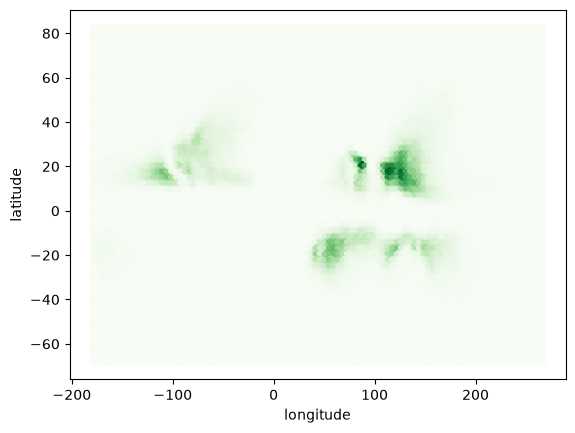

In [84]:
# 3.4
plt.hexbin(df3['LON'], df3['LAT'], gridsize = 100, cmap ='Greens')
plt.xlabel('longitude')
plt.ylabel('latitude')

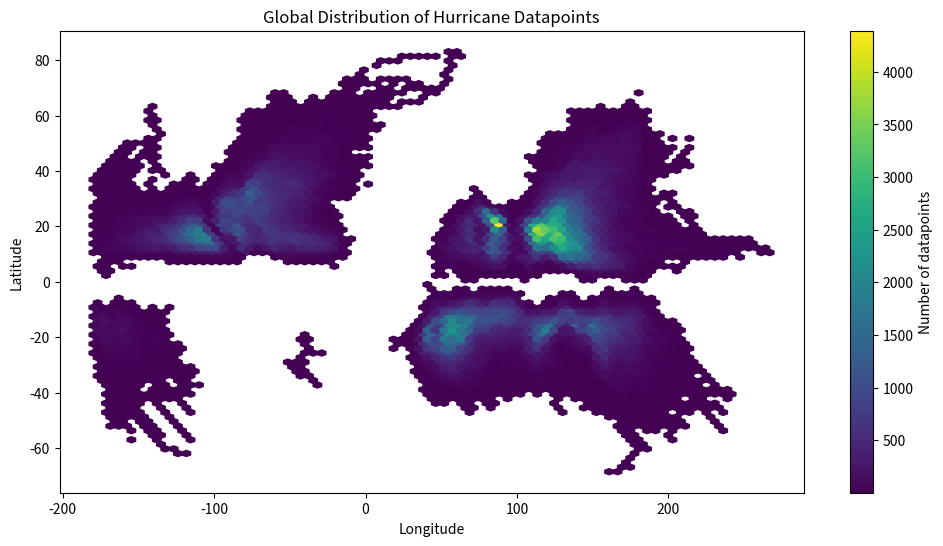

In [26]:
#助教添加
plt.figure(figsize=(12, 6))
plt.hexbin(df3["LON"], df3["LAT"], gridsize=80, mincnt=1, cmap="viridis")
plt.colorbar(label="Number of datapoints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Distribution of Hurricane Datapoints")
plt.show()

### 代码可以运行但是绘制六边形图可以用mincnt=1来选择至少有一个点才着色-1

### --------------------------------------------------------------------------------------------

Text(0, 0.5, 'latitude')

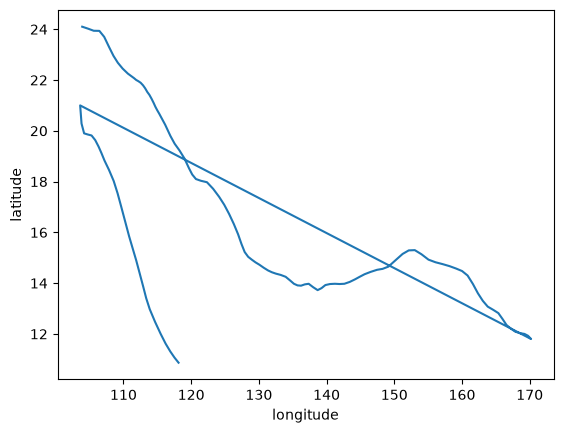

In [85]:
# 3.5
[lon, lat] = [df3.loc[df3['NAME'] == 'MANGKHUT']['LON'], df3.loc[df3['NAME'] == 'MANGKHUT']['LAT']]
plt.plot(lon, lat)
plt.xlabel('longitude')
plt.ylabel('latitude')

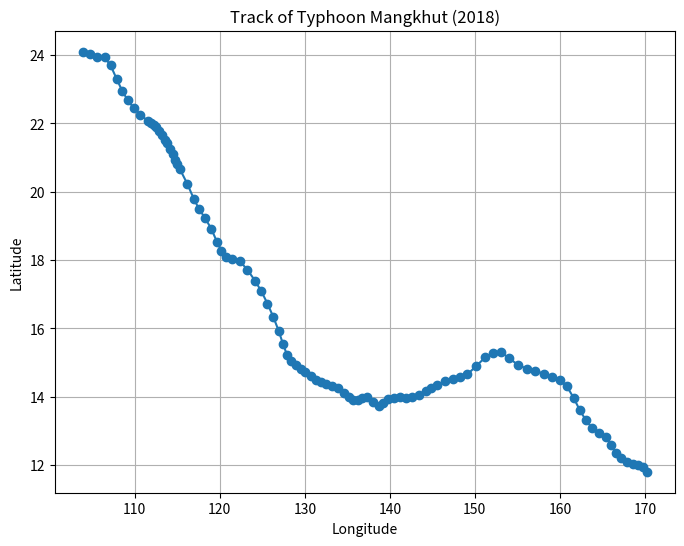

In [27]:
#助教添加
mangkhut = df3[
    (df3["SEASON"] == 2018)
    & (df3["NAME"] == "MANGKHUT")
].sort_values("ISO_TIME")

plt.figure(figsize=(8, 6))
plt.plot(mangkhut["LON"], mangkhut["LAT"], marker="o")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.grid()
plt.show()

### 代码可以运行但是没有根据题目筛选2018年的数据-2
### --------------------------------------------------------------------------------------------

In [31]:
# 3.6
df3_new = df3.loc[(df3['SEASON'] >= 1970) & ((df3['BASIN'] == 'EP') | (df3['BASIN'] == 'WP'))]
df3_new.copy()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,NaN,1006.0,tokyo,main,1088,1088.0,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,NaN,NaN,NaN,main,1109,1109.0,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,NaN,1002.0,tokyo,main,1143,1143.0,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,NaN,NaN,NaN,main,1171,1168.0,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,NaN,998.0,tokyo,main,1182,1179.0,_OO___________
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707085,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 15:00:00,TS,13.99570,-90.294,NaN,NaN,NaN,PROVISIONAL,0,0.0,P_____________
707086,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 18:00:00,NR,14.50000,-91.000,NaN,NaN,NaN,PROVISIONAL,0,NaN,O_____________
707174,2022286N15151,2022,80,WP,MM,NOT_NAMED,2022-10-12 12:00:00,NR,15.20000,151.300,NaN,NaN,NaN,PROVISIONAL,1985,1974.0,O_____________
707175,2022286N15151,2022,80,WP,MM,NOT_NAMED,2022-10-12 15:00:00,NR,15.05000,151.325,NaN,NaN,NaN,PROVISIONAL,1974,1952.0,P_____________


/tmp/ipykernel_1152784/570056214.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3_new['YEAR'] = df3_new['ISO_TIME'].dt.year
/tmp/ipykernel_1152784/570056214.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3_new['MONTH'] = df3_new['ISO_TIME'].dt.month
/tmp/ipykernel_1152784/570056214.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.

Text(0, 0.5, 'the number of datapoints')

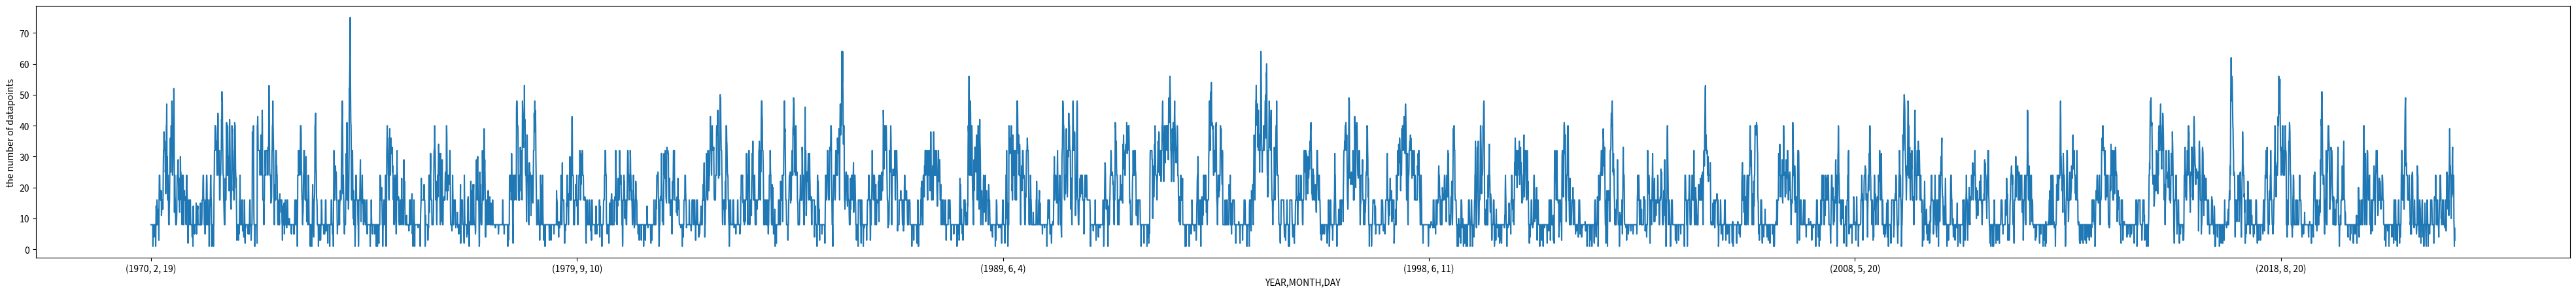

In [29]:
# 3.7
fig, ax = plt.subplots(figsize=(50, 5))
df3_new['YEAR'] = df3_new['ISO_TIME'].dt.year
df3_new['MONTH'] = df3_new['ISO_TIME'].dt.month
df3_new['DAY'] = df3_new['ISO_TIME'].dt.day
df3_new.groupby(['YEAR','MONTH','DAY']).size().plot()
plt.ylabel('the number of datapoints')

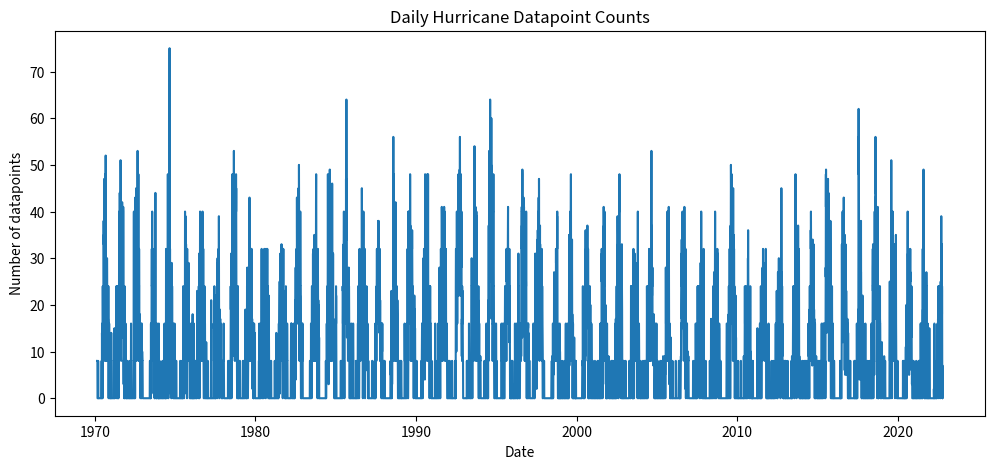

In [32]:
#助教添加
daily_counts = (
    df3_new.set_index("ISO_TIME")
    .resample("D")
    .size()
    .rename("count")
)

plt.figure(figsize=(12, 5))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel("Date")
plt.ylabel("Number of datapoints")
plt.title("Daily Hurricane Datapoint Counts")
plt.show()

### 代码可以运行但是有观测日期的计数正确，但遗漏零计数日期-1
### --------------------------------------------------------------------------------------------

DOY
1      7.545455
2      8.000000
3      6.727273
4      7.750000
5      8.750000
         ...   
362    8.315789
363    6.947368
364    8.000000
365    8.454545
366    6.500000
Length: 366, dtype: float64


/tmp/ipykernel_1152784/3827901464.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3_new['DOY'] = df3_new['ISO_TIME'].dt.dayofyear


Text(0, 0.5, 'the climatology of datapoint counts')

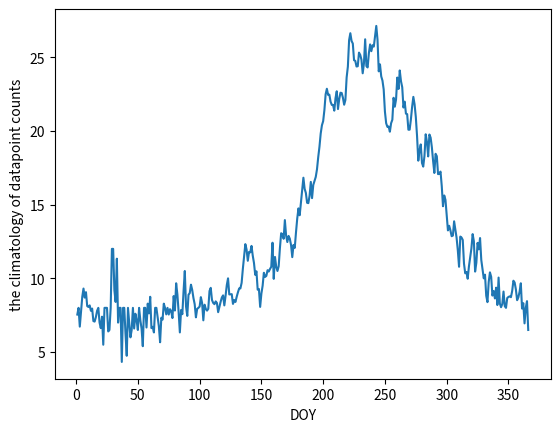

In [30]:
# 3.8
df3_new['DOY'] = df3_new['ISO_TIME'].dt.dayofyear
df38 = df3_new.groupby(['YEAR','DOY']).size().groupby('DOY').mean()
print(df38)
df38.plot()
plt.ylabel('the climatology of datapoint counts')

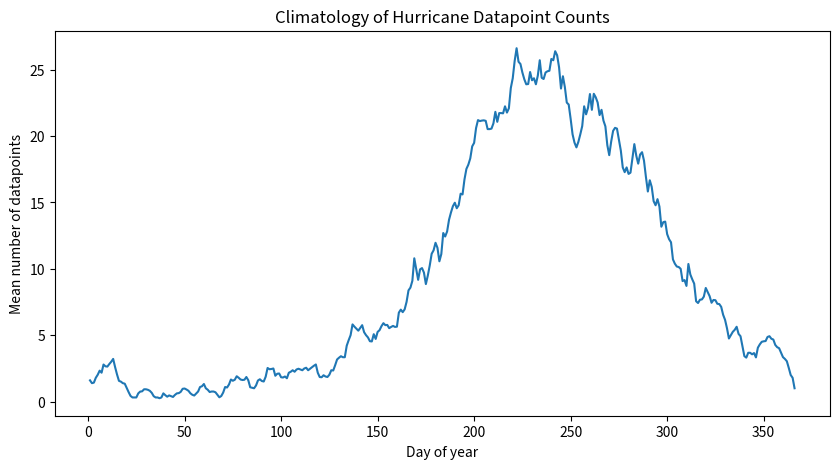

In [33]:
#助教添加
daily = daily_counts.to_frame()
daily["day_of_year"] = daily.index.dayofyear
climatology = daily.groupby("day_of_year")["count"].mean()

plt.figure(figsize=(10, 5))
plt.plot(climatology.index, climatology.values)
plt.xlabel("Day of year")
plt.ylabel("Mean number of datapoints")
plt.title("Climatology of Hurricane Datapoint Counts")
plt.show()

### 代码可以运行只对有观测的年份求平均，气候态偏大-1
### --------------------------------------------------------------------------------------------

YEAR  DOY
1970  50      1.500000
      51      0.000000
      52      0.833333
      53      1.400000
      54      2.600000
               ...    
2022  277    -8.980769
      278   -11.693878
      282   -17.301887
      283   -12.769231
      285   -15.269231
Length: 10817, dtype: float64


Text(0, 0.5, 'the anomaly of daily counts from the climatology')

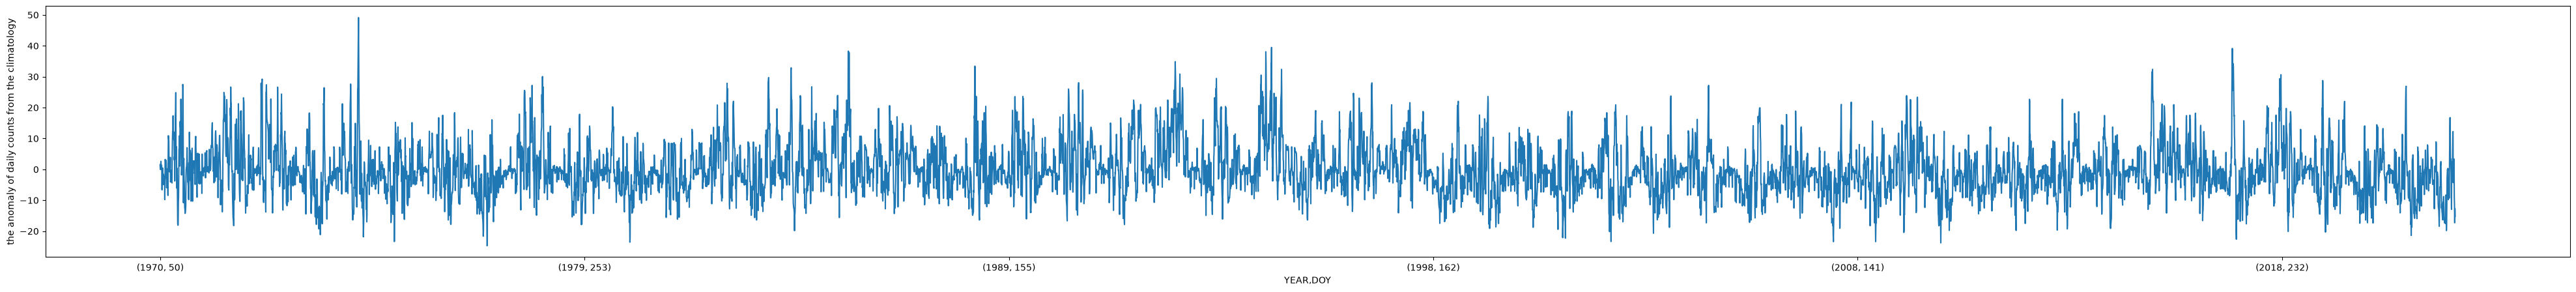

In [47]:
# 3.9
fig, ax = plt.subplots(figsize=(50, 5))
anom = df3_new.groupby(['YEAR','DOY']).size() - df38
print(anom)
anom.plot()
plt.ylabel('the anomaly of daily counts from the climatology')

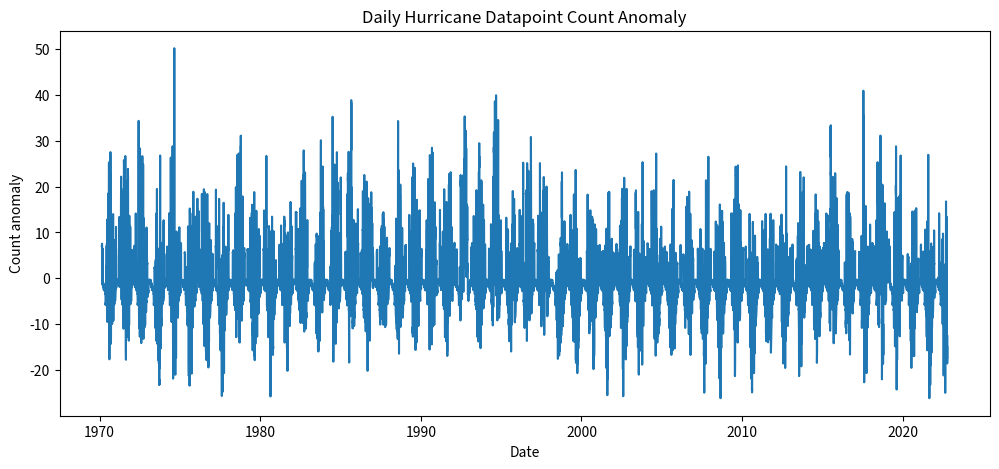

In [34]:
#助教添加
daily["climatology"] = daily["day_of_year"].map(climatology)
daily["anomaly"] = daily["count"] - daily["climatology"]

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily["anomaly"])
plt.xlabel("Date")
plt.ylabel("Count anomaly")
plt.title("Daily Hurricane Datapoint Count Anomaly")
plt.show()

### 减法公式和索引对齐正确，沿用了上题错误-1
### --------------------------------------------------------------------------------------------

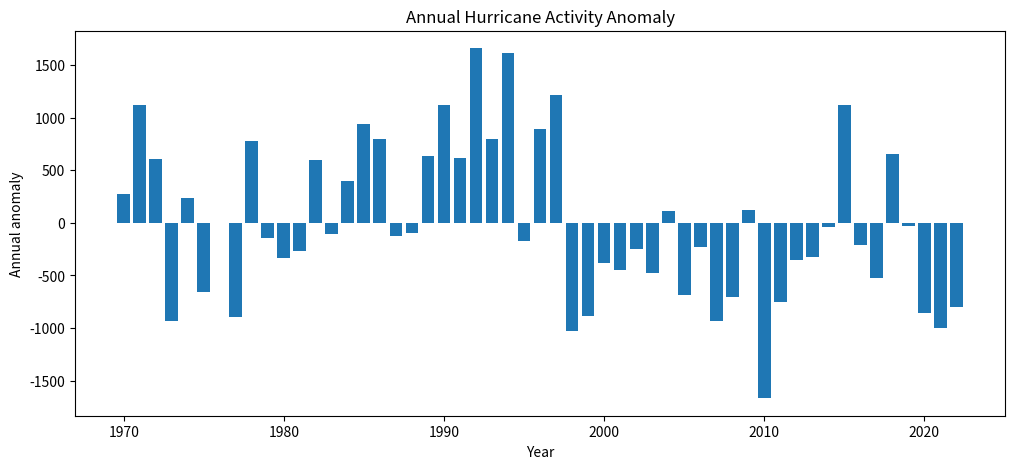

Highest anomaly years:
ISO_TIME
1992-01-01    1660.725327
1994-01-01    1611.725327
1997-01-01    1215.725327
1990-01-01    1121.725327
2015-01-01    1119.725327
Name: anomaly, dtype: float64
Lowest anomaly years:
ISO_TIME
2010-01-01   -1668.274673
1998-01-01   -1033.274673
2021-01-01   -1004.274673
2007-01-01    -935.274673
1973-01-01    -933.274673
Name: anomaly, dtype: float64


In [35]:
# 3.10
#助教添加
annual_anomaly = daily["anomaly"].resample("YS").sum()

plt.figure(figsize=(12, 5))
plt.bar(annual_anomaly.index.year, annual_anomaly.values)
plt.xlabel("Year")
plt.ylabel("Annual anomaly")
plt.title("Annual Hurricane Activity Anomaly")
plt.show()

print("Highest anomaly years:")
print(annual_anomaly.sort_values(ascending=False).head())
print("Lowest anomaly years:")
print(annual_anomaly.sort_values().head())

### 未作答-5
### --------------------------------------------------------------------------------------------

### 代码和报告没有结果的分析-1
### 得分：36/50
### --------------------------------------------------------------------------------------------

In [36]:
# 4.1
df4 = pd.read_csv('US10adam004.csv',
                 parse_dates=['DATE'])
df4

FileNotFoundError: [Errno 2] No such file or directory: 'US10adam004.csv'

Text(0, 0.5, 'PRCP')

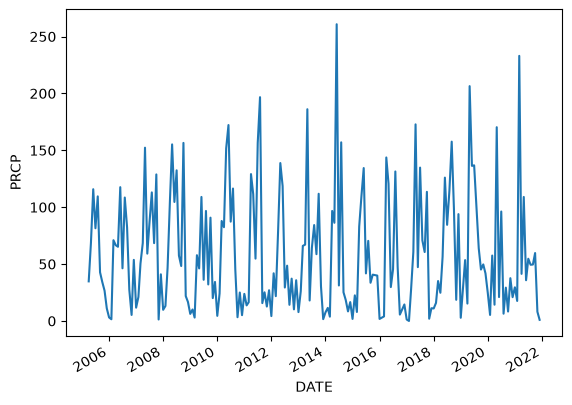

In [61]:
# 4.2
df4.set_index('DATE')['PRCP'].plot()
plt.ylabel('PRCP')

In [65]:
# 4.3
print(df4["PRCP"].min(), df4["PRCP"].max())
print(df4["PRCP"].mean())
print(df4["PRCP"].skew())
print(df4["PRCP"].kurt())

0.0 260.8
59.254545454545465
1.1299243502658727
0.9626071734117443


### 第一问没有筛选数据，虽然报告中说无缺测、无负值但可以对年份或者异常值筛选，其他两题代码正确且有一定分析
### 建议后续作业可以在文件夹中放入原始数据方便助教运行并检查代码，并且建议每行代码有相应注释
### 得分：14/15
### --------------------------------------------------------------------------------------------